# BRCA ST patient E — pan-cancer Hist2Pheno

Andersson et al. *Nat Commun* 2021. HER2ST **E**: patient 23567, sections E1–E3, about 0.69 µm/px. No cell-type ground truth.
Predictions are the pan-cancer **cross-section** checkpoint `D_emph_L2_spatial_pancancer` (L1 / L12 / L2), spatial k=8.

JPEG 72 dpi is not used. µm/px is the 200 µm ST spot pitch. UNI rescales by `mpp/0.5` so the 16 px crop is **8 µm**.

One notebook per patient so the file does not store all 36 slides. Full-resolution PNGs stay in `data/ST/BRCA/pred_pancancer_section/figures/`.

```bash
SAMPLE=E bash code/External_val/BRCA_ST/demo.sh all
```


In [1]:
import io
import shutil
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display
from PIL import Image as PILImage

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
if not (REPO / "code").is_dir():
    REPO = Path("/nobackup2/users/lingyu/Python/Hist2Pheno")
sys.path.insert(0, str(REPO / "code" / "External_val" / "BRCA_ST"))

from brca_st_external import (  # noqa: E402
    PRED_ROOT,
    composition_table,
    discover_samples,
    geometry,
    sample_paths,
    ensure_l2_probs,
    cmd_plot,
)

PATIENT = "E"
PREVIEW_PX = 1100
group = discover_samples(PATIENT)
fig_dir = PRED_ROOT / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)
print(f"{PATIENT}  n={len(group)}")
for sample in group:
    g = geometry(sample)
    print(
        f"{sample}  mpp={g['mpp_um']:.4f} µm/px  "
        f"native16={g['patch_um_if_native_16px']:.2f} µm  "
        f"after rescale={g['patch_um_after_rescale']:.1f} µm  "
        f"scale={g['scale']:.4f}  ({g['mpp_source']})"
    )
    print(f"  pred exists: {sample_paths(sample)['pred'].is_file()}")


def show_preview(path: Path) -> None:
    """Embed a small JPEG. The full PNG stays on disk."""
    im = PILImage.open(path)
    im.thumbnail((PREVIEW_PX, PREVIEW_PX))
    buf = io.BytesIO()
    im.convert("RGB").save(buf, format="JPEG", quality=70)
    display(Image(data=buf.getvalue(), format="jpeg"))
    print(path)


E  n=3
HE_BT23567_D2  mpp=0.6874 µm/px  native16=11.00 µm  after rescale=8.0 µm  scale=1.3748  (ST 200 µm spot pitch (E1))
  pred exists: True
HE_BT23567_E1  mpp=0.6874 µm/px  native16=11.00 µm  after rescale=8.0 µm  scale=1.3749  (ST 200 µm spot pitch (E2))
  pred exists: True
HE_BT23567_E2  mpp=0.6878 µm/px  native16=11.00 µm  after rescale=8.0 µm  scale=1.3755  (ST 200 µm spot pitch (E3))
  pred exists: True


## E — composition and spatial labels


===== E L1 =====


fraction                                 mean_conf  \
sample      HE_BT23567_D2 HE_BT23567_E1 HE_BT23567_E2 HE_BT23567_D2   
class                                                                 
Immune              0.883         0.852         0.859         0.701   
Stromal             0.046         0.074         0.060         0.444   
Endothelial         0.034         0.053         0.051         0.423   
Epithelial          0.037         0.021         0.029         0.553   

                                                    n                \
sample      HE_BT23567_E1 HE_BT23567_E2 HE_BT23567_D2 HE_BT23567_E1   
class                                                                 
Immune              0.688         0.705      155891.0      149508.0   
Stromal             0.445         0.448        8081.0       12937.0   
Endothelial         0.424         0.428        6030.0        9355.0   
Epithelial          0.492         0.525        6507.0        3653.0   

                           
sample      HE_BT23567_E2  
class                      
Immune           148261.0  
Stromal           10439.0  
Endothelial        8816.0  
Epithelial         5035.0

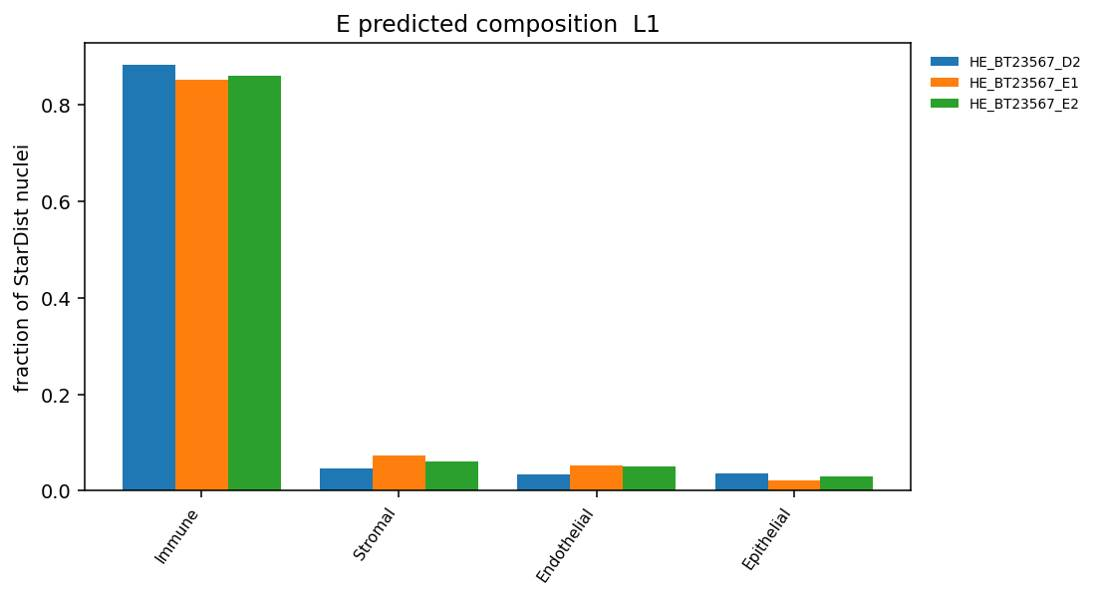

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/E_composition_L1.png

===== E L12 =====


fraction                                 mean_conf  \
sample      HE_BT23567_D2 HE_BT23567_E1 HE_BT23567_E2 HE_BT23567_D2   
class                                                                 
T_cell              0.743         0.815         0.790         0.508   
B_Plasma            0.154         0.089         0.108         0.476   
Stromal             0.040         0.062         0.055         0.361   
Myeloid             0.033         0.016         0.021         0.350   
Epithelial          0.026         0.014         0.018         0.479   
Tumor               0.003         0.001         0.004         0.410   
Endothelial         0.002         0.003         0.004         0.296   

                                                    n                \
sample      HE_BT23567_E1 HE_BT23567_E2 HE_BT23567_D2 HE_BT23567_E1   
class                                                                 
T_cell              0.526         0.526      131081.0      142991.0   
B_Plasma            0.460         0.474       27095.0       15675.0   
Stromal             0.359         0.365        7035.0       10796.0   
Myeloid             0.311         0.319        5840.0        2737.0   
Epithelial          0.419         0.456        4634.0        2455.0   
Tumor               0.374         0.403         468.0         251.0   
Endothelial         0.303         0.300         356.0         548.0   

                           
sample      HE_BT23567_E2  
class                      
T_cell           136333.0  
B_Plasma          18696.0  
Stromal            9418.0  
Myeloid            3645.0  
Epithelial         3164.0  
Tumor               653.0  
Endothelial         642.0

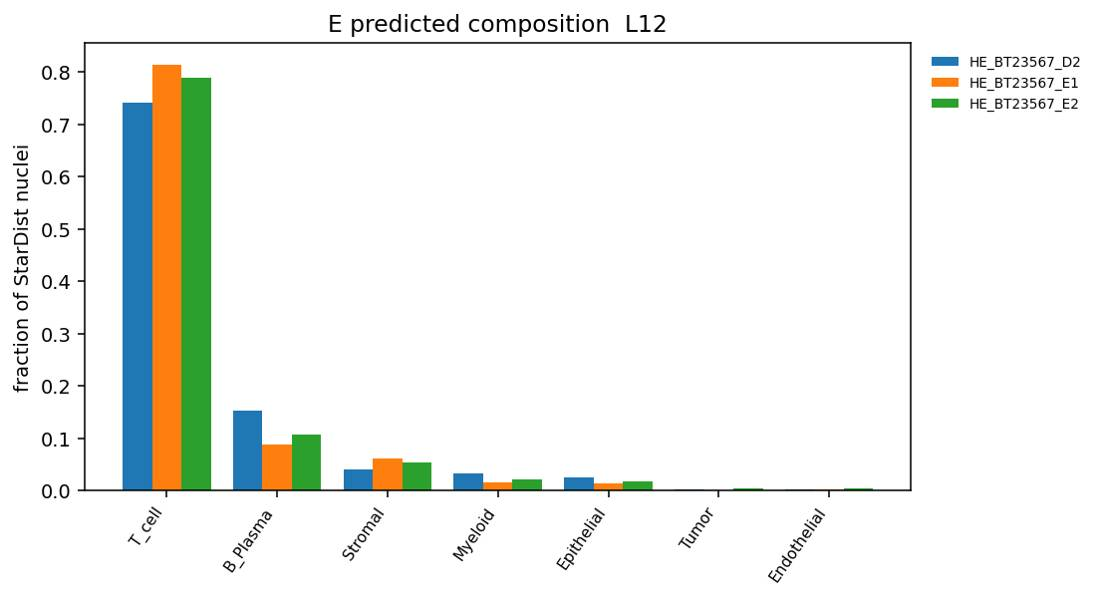

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/E_composition_L12.png

===== E L2 =====


fraction                                 mean_conf  \
sample            HE_BT23567_D2 HE_BT23567_E1 HE_BT23567_E2 HE_BT23567_D2   
class                                                                       
B_cell                    0.830         0.754         0.759         0.535   
CD4_T                     0.074         0.124         0.121         0.360   
Fibroblast                0.047         0.075         0.063         0.264   
Endothelial               0.011         0.017         0.019         0.225   
Epithelial                0.008         0.003         0.006         0.296   
Injury_epithelial         0.007         0.006         0.006         0.343   
DC                        0.007         0.002         0.003         0.283   
Stromal                   0.005         0.005         0.006         0.308   
CD8_T                     0.003         0.005         0.003         0.236   
Plasma                    0.002         0.003         0.004         0.299   
DCIS                      0.003         0.001         0.002         0.318   
Neutrophil                0.001         0.003         0.002         0.213   
Tumor                     0.001         0.001         0.002         0.276   
Myoepithelial             0.001         0.001         0.002         0.217   
Tregs                     0.001         0.001         0.002         0.244   
Macrophage                0.000         0.000         0.000         0.147   
Alveolar                  0.000         0.000         0.000         0.171   
Myofibroblast               NaN         0.000         0.000           NaN   

                                                          n                \
sample            HE_BT23567_E1 HE_BT23567_E2 HE_BT23567_D2 HE_BT23567_E1   
class                                                                       
B_cell                    0.493         0.515      146465.0      132221.0   
CD4_T                     0.356         0.360       13051.0       21781.0   
Fibroblast                0.272         0.270        8282.0       13173.0   
Endothelial               0.232         0.232        1967.0        2940.0   
Epithelial                0.250         0.269        1422.0         605.0   
Injury_epithelial         0.290         0.328        1186.0         981.0   
DC                        0.248         0.258        1162.0         321.0   
Stromal                   0.290         0.312         812.0         821.0   
CD8_T                     0.231         0.227         452.0         796.0   
Plasma                    0.269         0.284         350.0         559.0   
DCIS                      0.257         0.297         572.0         246.0   
Neutrophil                0.233         0.233         173.0         449.0   
Tumor                     0.252         0.274         163.0         133.0   
Myoepithelial             0.204         0.216         227.0         146.0   
Tregs                     0.247         0.243         196.0         246.0   
Macrophage                0.146         0.156          26.0          20.0   
Alveolar                  0.182         0.221           3.0          13.0   
Myofibroblast             0.161         0.203           NaN           2.0   

                                 
sample            HE_BT23567_E2  
class                            
B_cell                 131002.0  
CD4_T                   20823.0  
Fibroblast              10937.0  
Endothelial              3271.0  
Epithelial                960.0  
Injury_epithelial        1078.0  
DC                        516.0  
Stromal                  1006.0  
CD8_T                     531.0  
Plasma                    712.0  
DCIS                      381.0  
Neutrophil                422.0  
Tumor                     341.0  
Myoepithelial             264.0  
Tregs                     260.0  
Macrophage                 32.0  
Alveolar                   10.0  
Myofibroblast               5.0

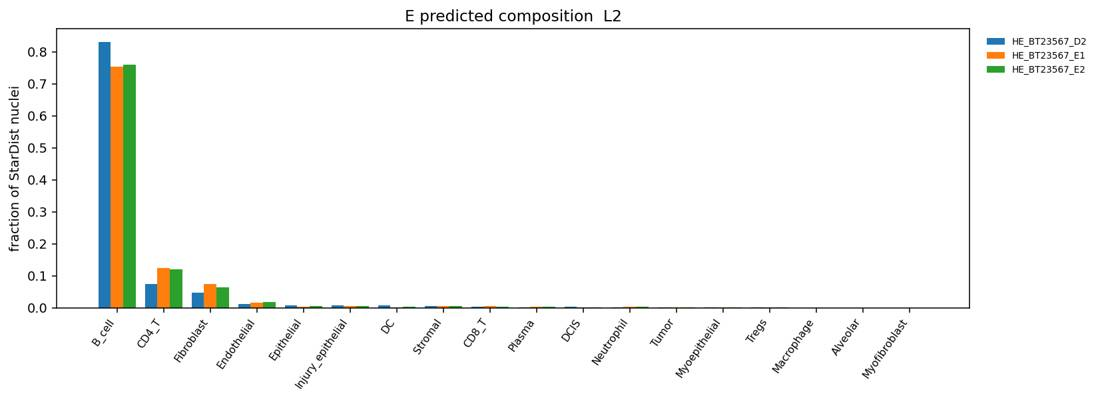

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/E_composition_L2.png
HE_BT23567_D2


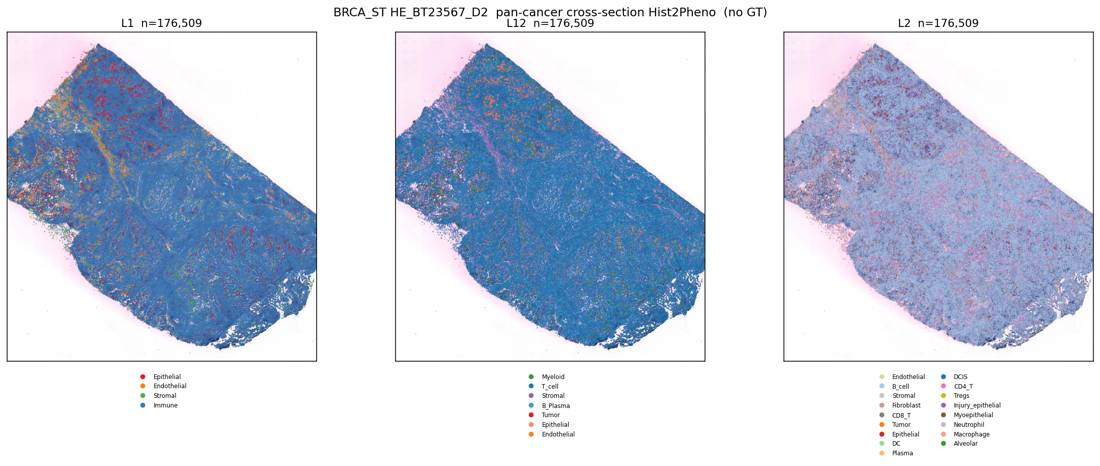

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT23567_D2_spatial_L1_L12_L2.png
HE_BT23567_E1


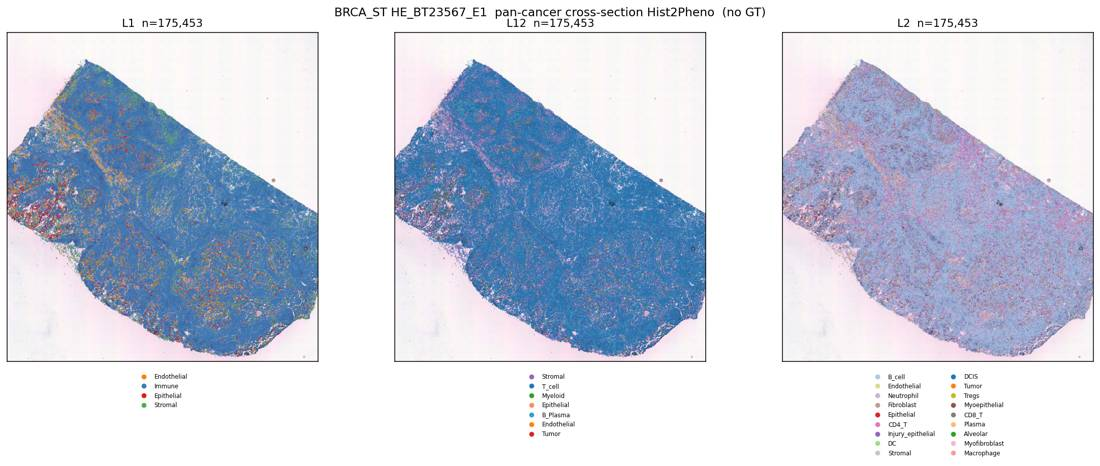

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT23567_E1_spatial_L1_L12_L2.png
HE_BT23567_E2


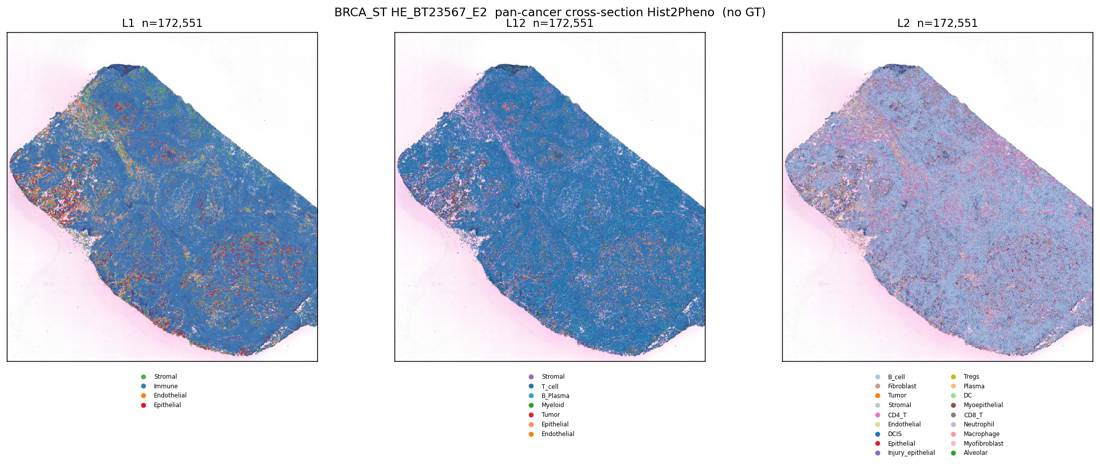

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT23567_E2_spatial_L1_L12_L2.png


In [2]:
missing = [s for s in group if not sample_paths(s)["pred"].is_file()]
if missing:
    raise FileNotFoundError(
        f"No predictions yet for {PATIENT}: "
        + ", ".join(missing)
        + f". Run: SAMPLE={PATIENT} bash code/External_val/BRCA_ST/demo.sh all"
    )

display(Markdown(f"## {PATIENT} — composition and spatial labels"))
comp = composition_table(group)
for head in ("L1", "L12", "L2"):
    sub = comp.loc[comp["head"] == head].copy()
    order = sub.groupby("class")["fraction"].max().sort_values(ascending=False).index
    wide = (
        sub.pivot_table(index="class", columns="sample", values=["fraction", "n", "mean_conf"])
        .reindex(order)
    )
    print(f"\n===== {PATIENT} {head} =====")
    display(wide.round(3))

    classes = list(order)
    sections = list(dict.fromkeys(sub["sample"]))
    fig, ax = plt.subplots(figsize=(max(8, 0.55 * len(classes) + 2), 4.4))
    x = range(len(classes))
    width = 0.8 / max(len(sections), 1)
    for i, section in enumerate(sections):
        ss = sub.loc[sub["sample"] == section].set_index("class")
        vals = [float(ss.loc[c, "fraction"]) if c in ss.index else 0.0 for c in classes]
        ax.bar([xi + i * width for xi in x], vals, width=width, label=section)
    ax.set_xticks([xi + width * (len(sections) - 1) / 2 for xi in x])
    ax.set_xticklabels(classes, rotation=55, ha="right", fontsize=8)
    ax.set_ylabel("fraction of StarDist nuclei")
    ax.set_title(f"{PATIENT} predicted composition  {head}")
    ax.legend(frameon=False, fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.tight_layout()
    out = fig_dir / f"{PATIENT}_composition_{head}.png"
    fig.savefig(out, dpi=140, bbox_inches="tight")
    plt.close(fig)
    show_preview(out)

spatial_missing = [
    s for s in group if not (fig_dir / f"{s}_spatial_L1_L12_L2.png").is_file()
]
if spatial_missing:
    cmd_plot(group)
    for head in ("L1", "L12", "L2"):
        src = fig_dir / f"composition_{head}.png"
        if src.is_file():
            shutil.copy(src, fig_dir / f"{PATIENT}_composition_{head}.png")
for sample in group:
    print(sample)
    show_preview(fig_dir / f"{sample}_spatial_L1_L12_L2.png")


## Histology-derived niche indices (TLS / SRI / TNI)

Same implementation as `code/Xenium_lung/histology_derived_niche_index.ipynb` §3, via `Hist2Pheno_pkg/histology_niche_index.py`. Lung ARI / FRI are not used.

Scores use **L2 softmax**, not the argmax label. `ensure_l2_probs` caches `{sample}_l2_probs.npz`.

| Index | Abundance | Spatial (radius R) |
|--|--|--|
| **TLS** | sum(B_cell + Plasma + CD4_T + CD8_T + Tregs + DC) | `(B_local × T_local × DC_local)^(1/3)` |
| **SRI** | (Fibroblast + Myofibroblast + Stromal) / epithelium | Fib_local / Epi_local |
| **TNI** | (fibroblast + Macrophage + Endothelial) / epithelium | `(Fib × Mac × Endo)^(1/3) / Epi_local` |

Epithelium = Epithelial, Tumor, Alveolar, Injury_epithelial, DCIS, Myoepithelial. NK is left out of TLS. `spatial_HE` is native JPEG pixels, so R = **55 µm** uses this slide's own µm/px. TLS, SRI, and TNI are each a 1×3 row. This notebook embeds a resized preview; the saved PNG is full resolution.


In [3]:
import importlib

for _p in (REPO / "code" / "Hist2Pheno_pkg", REPO / "code" / "Xenium_lung"):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import histology_niche_index as hni
importlib.reload(hni)
import histology_derived_niche_index as hdni
importlib.reload(hdni)
from histology_niche_index import OrganNicheConfig

import anndata as ad

TLS_RADIUS_UM = 55.0
RECOMPUTE_NICHE = False

BRCA_ST_NICHE = OrganNicheConfig(
    pan_organ="pancancer_brca_st",
    tls_b=("B_cell", "Plasma"),
    tls_t=("CD4_T", "CD8_T", "Tregs"),
    tls_dc=("DC",),
    epithelium=(
        "Epithelial", "Tumor", "Alveolar",
        "Injury_epithelial", "DCIS", "Myoepithelial",
    ),
    fibroblast=("Fibroblast", "Myofibroblast", "Stromal"),
    endothelial=("Endothelial",),
    macrophage=("Macrophage",),
    um_per_he_pixel=float(geometry(group[0])["mpp_um"]),
    spatial_radius_um=TLS_RADIUS_UM,
    cohort="BRCA_ST",
)
display(hni.index_formula_table(BRCA_ST_NICHE))


,index,formula
0,TLS,sum(B_cell+ Plasma+ CD4_T+ CD8_T+ Tregs+ DC)
1,TLS_spatial,(B_local × T_local × DC_local)^(1/3) within ra...
2,SRI_ratio,Fibroblast+Myofibroblast+Stromal / Epithelial+...
3,SRI_spatial,Fib_local / Epi_local within radius R μm
4,TNI_ratio,(Fibroblast+Myofibroblast+Stromal + Macrophage...
5,TNI_spatial,(Fib_local × myeloid_local × Endo_local)^(1/3)...


## E — TLS / SRI / TNI

[probs] cache /nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/HE_BT23567_D2/HE_BT23567_D2_l2_probs.npz  (176509, 20)
[niche] wrote /nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/HE_BT23567_D2/HE_BT23567_D2_niche_indices.h5ad  n=176,509
  TLS hotspot: {'n_cells_total': 176509, 'n_candidate_cells': 8826, 'fraction_candidate': 0.050003115988419854, 'max_tls_spatial': 0.2450335256481906, 'mean_tls_spatial_candidate': 0.2057656551996724, 'centroid_x': 5797.8850674623945, 'centroid_y': 6300.854208621421}
  mean TLS=0.795  TLS_spatial=0.172  SRI=14.531  TNI=27.794
[probs] cache /nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/HE_BT23567_E1/HE_BT23567_E1_l2_probs.npz  (175453, 20)
[niche] wrote /nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/HE_BT23567_E1/HE_BT23567_E1_niche_indices.h5ad  n=175,453
  TLS hotspot: {'n_cells_total': 175453, 'n_candidate_cells': 8773, 'fraction_

,sample,n,TLS_mean,TLS_median,TLS_p95,TLS_max,TLS_spatial_mean,TLS_spatial_median,TLS_spatial_p95,TLS_spatial_max,pearson,spearman,top5_jaccard,abundance_top5_also_spatial_top5,TLS_spatial_mean_in_abundance_top5,TLS_mean_in_spatial_top5
0,HE_BT23567_D2,176509,0.795,0.859,0.972,0.995,0.172,0.172,0.198,0.245,0.237,0.051,0.008,0.017,0.168,0.796
1,HE_BT23567_E1,175453,0.770,0.833,0.967,0.994,0.164,0.165,0.183,0.218,0.368,0.207,0.015,0.029,0.164,0.807
2,HE_BT23567_E2,172551,0.778,0.849,0.972,0.995,0.165,0.167,0.187,0.236,0.385,0.184,0.010,0.020,0.164,0.799


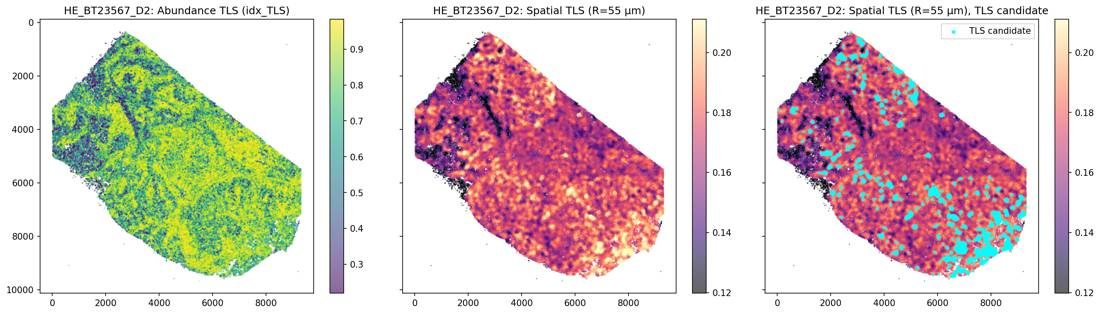

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT23567_D2_TLS_abundance_vs_spatial.png


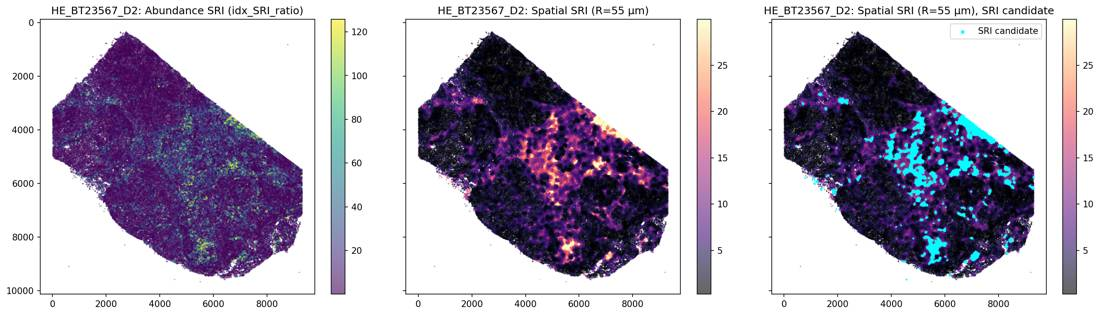

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT23567_D2_SRI_abundance_vs_spatial.png


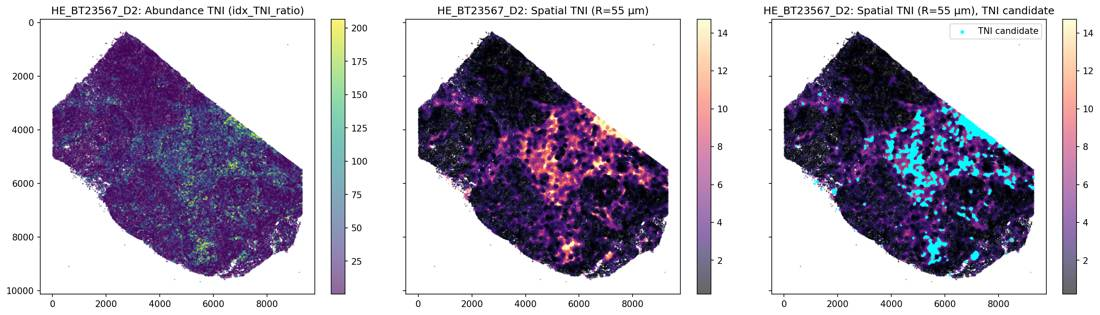

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT23567_D2_TNI_abundance_vs_spatial.png


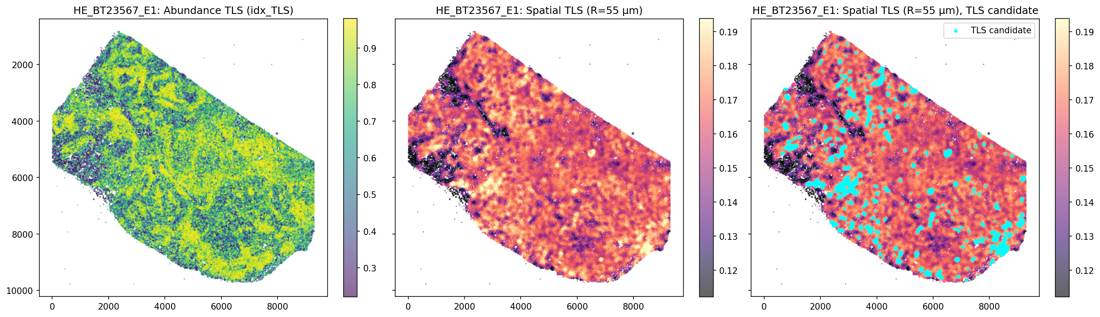

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT23567_E1_TLS_abundance_vs_spatial.png


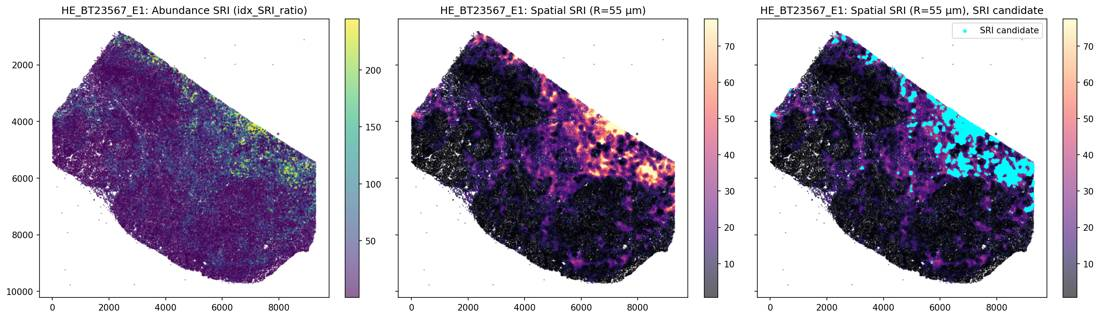

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT23567_E1_SRI_abundance_vs_spatial.png


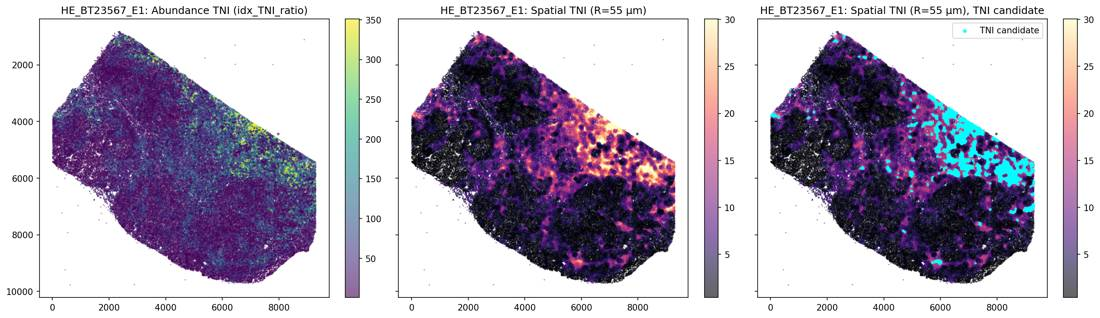

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT23567_E1_TNI_abundance_vs_spatial.png


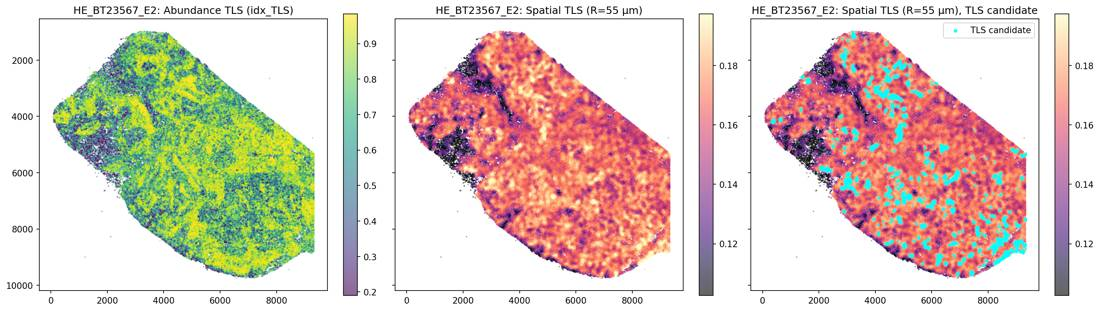

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT23567_E2_TLS_abundance_vs_spatial.png


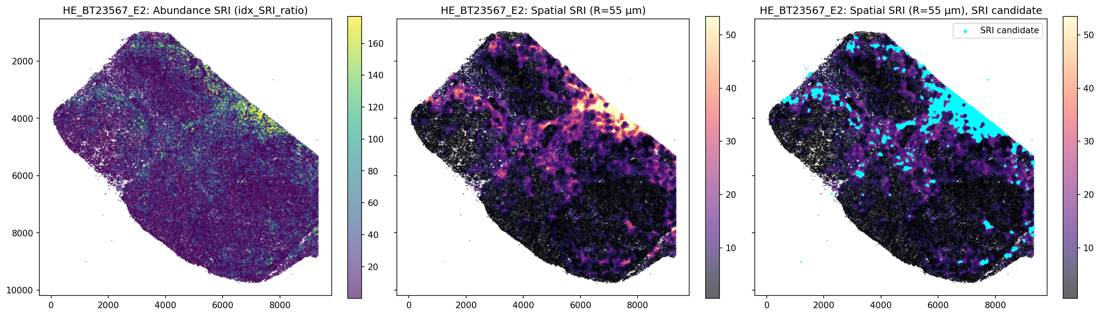

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT23567_E2_SRI_abundance_vs_spatial.png


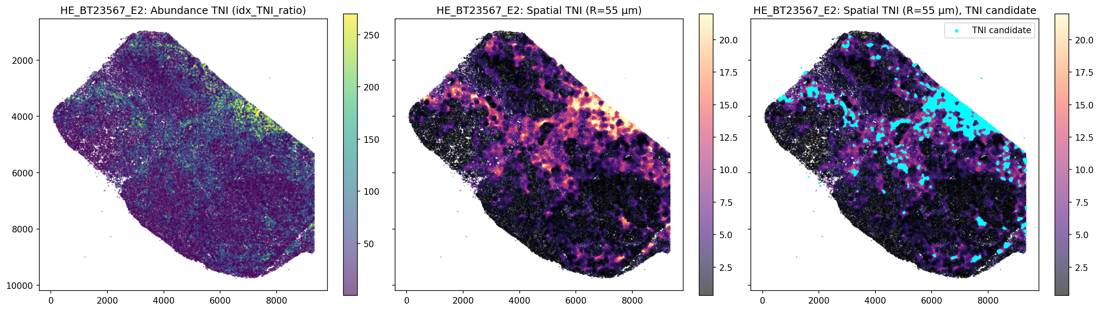

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT23567_E2_TNI_abundance_vs_spatial.png


In [4]:
import numpy as np

missing = [s for s in group if not sample_paths(s)["pred"].is_file()]
if missing:
    raise FileNotFoundError(
        f"No predictions yet for {PATIENT}: "
        + ", ".join(missing)
        + f". Run: SAMPLE={PATIENT} bash code/External_val/BRCA_ST/demo.sh all"
    )
display(Markdown(f"## {PATIENT} — TLS / SRI / TNI"))
frames = {}
for sample in group:
    paths = sample_paths(sample)
    niche_path = paths["pred"].with_name(f"{sample}_niche_indices.h5ad")
    mpp = float(geometry(sample)["mpp_um"])
    if niche_path.is_file() and not RECOMPUTE_NICHE:
        cached = ad.read_h5ad(niche_path)
        df = cached.obs.copy()
        xy = np.asarray(cached.obsm["spatial_HE"], dtype=np.float64)
        df["coord_x"] = xy[:, 0]
        df["coord_y"] = xy[:, 1]
        print(f"[niche] cache {niche_path.name}  n={len(df):,}  µm/px={mpp:.4f}")
    else:
        probs, class_names = ensure_l2_probs(sample)
        absent = hni.missing_index_cell_types(class_names, BRCA_ST_NICHE)
        if absent:
            raise RuntimeError(f"{sample} missing niche compartments: {absent}")
        pred = ad.read_h5ad(paths["pred"])
        coords = np.asarray(pred.obsm["spatial_HE"], dtype=np.float64)
        df = pred.obs.copy()
        df["coord_x"] = coords[:, 0]
        df["coord_y"] = coords[:, 1]
        df = hni.add_abundance_indices(df, probs, class_names, BRCA_ST_NICHE)
        df = hni.add_spatial_indices(
            df, probs, class_names, coords, BRCA_ST_NICHE,
            radius_um=TLS_RADIUS_UM,
            um_per_pixel=mpp,
        )
        out = ad.AnnData(obs=df.drop(columns=["coord_x", "coord_y"]))
        out.obsm["spatial_HE"] = coords
        out.uns["tls_radius_um"] = TLS_RADIUS_UM
        out.uns["um_per_px"] = mpp
        out.write_h5ad(niche_path)
        print(f"[niche] wrote {niche_path}  n={len(df):,}")
    frames[sample] = df
    print(f"  TLS hotspot: {hni.summarize_tls_hotspots(df)}")
    print(
        f"  mean TLS={df['idx_TLS'].mean():.3f}  TLS_spatial={df['idx_TLS_spatial'].mean():.3f}  "
        f"SRI={df['idx_SRI_ratio'].mean():.3f}  TNI={df['idx_TNI_ratio'].mean():.3f}"
    )

def tls_score_row(df, sample: str) -> dict:
    a = df["idx_TLS"].to_numpy(dtype=float)
    s = df["idx_TLS_spatial"].to_numpy(dtype=float)
    a_hi = a >= np.percentile(a, 95)
    s_hi = df["tls_candidate"].fillna(False).astype(bool).to_numpy()
    inter = int(np.logical_and(a_hi, s_hi).sum())
    union = int(np.logical_or(a_hi, s_hi).sum())
    n_a = int(a_hi.sum())
    return {
        "sample": sample,
        "n": int(len(df)),
        "TLS_mean": float(np.mean(a)),
        "TLS_median": float(np.median(a)),
        "TLS_p95": float(np.percentile(a, 95)),
        "TLS_max": float(np.max(a)),
        "TLS_spatial_mean": float(np.mean(s)),
        "TLS_spatial_median": float(np.median(s)),
        "TLS_spatial_p95": float(np.percentile(s, 95)),
        "TLS_spatial_max": float(np.max(s)),
        "pearson": float(np.corrcoef(a, s)[0, 1]),
        "spearman": float(pd.Series(a).corr(pd.Series(s), method="spearman")),
        "top5_jaccard": (inter / union) if union else float("nan"),
        "abundance_top5_also_spatial_top5": (inter / n_a) if n_a else float("nan"),
        "TLS_spatial_mean_in_abundance_top5": float(s[a_hi].mean()) if n_a else float("nan"),
        "TLS_mean_in_spatial_top5": float(a[s_hi].mean()) if s_hi.any() else float("nan"),
    }

tls_quant = pd.DataFrame([tls_score_row(df, sample) for sample, df in frames.items()])
tls_quant_path = fig_dir / f"tls_score_summary_{PATIENT}.csv"
tls_quant.to_csv(tls_quant_path, index=False)
print(tls_quant_path)
display(tls_quant.round(3))

for sample, df in frames.items():
    fig, axes = hdni.plot_tls_abundance_vs_spatial(
        df,
        sample,
        radius_um=TLS_RADIUS_UM,
        use_entropy=False,
        split_spatial_candidates=True,
        point_size=0.15,
        candidate_size=1.2,
        save_path=fig_dir / f"{sample}_TLS_abundance_vs_spatial.png",
    )
    plt.close(fig)
    show_preview(fig_dir / f"{sample}_TLS_abundance_vs_spatial.png")
    for abundance_col, spatial_col, candidate_col, tag in (
        ("idx_SRI_ratio", "idx_SRI_spatial", "sri_candidate", "SRI"),
        ("idx_TNI_ratio", "idx_TNI_spatial", "tni_candidate", "TNI"),
    ):
        fig, axes = hdni.plot_tls_abundance_vs_spatial(
            df,
            sample,
            radius_um=TLS_RADIUS_UM,
            abundance_col=abundance_col,
            spatial_col=spatial_col,
            candidate_col=candidate_col,
            score_name=tag,
            use_entropy=False,
            split_spatial_candidates=True,
            point_size=0.15,
            candidate_size=1.2,
            save_path=fig_dir / f"{sample}_{tag}_abundance_vs_spatial.png",
        )
        plt.close(fig)
        show_preview(fig_dir / f"{sample}_{tag}_abundance_vs_spatial.png")
